In [1]:
#Bolli Yaswanth Melki , 92400133114 ,5EK2B
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
sns.set_style("whitegrid")

In [2]:
DATA_PATH = "diabetes.csv"

if not os.path.exists(DATA_PATH):
    try:
        from google.colab import files
        print("Upload 'diabetes.csv' from 01_Data_Analysis/:")
        uploaded = files.upload()
        DATA_PATH = next(iter(uploaded.keys()))
    except ImportError:
        raise FileNotFoundError(
            "diabetes.csv not found. Place it in the working directory or update DATA_PATH."
        )

df = pd.read_csv(DATA_PATH)
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (108, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
print("Dataset Info")
df.info()

print("\nMissing Values per Column")
print(df.isnull().sum())

print("\n Duplicate Rows")
print("Duplicates:", df.duplicated().sum())

df.describe().T

Dataset Info
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 108 entries, 0 to 107
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               108 non-null    int64  
 1   Glucose                   108 non-null    int64  
 2   BloodPressure             108 non-null    int64  
 3   SkinThickness             108 non-null    int64  
 4   Insulin                   108 non-null    int64  
 5   BMI                       108 non-null    float64
 6   DiabetesPedigreeFunction  108 non-null    float64
 7   Age                       108 non-null    int64  
 8   Outcome                   108 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 7.7 KB

Missing Values per Column
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunct

,count,mean,std,min,25%,50%,75%,max
Pregnancies,108.0,4.370370,3.569320,0.000,1.000,4.0000,7.00000,15.000
Glucose,108.0,118.194444,33.399160,0.000,98.500,113.5000,139.50000,197.000
BloodPressure,108.0,68.592593,22.038215,0.000,64.000,72.0000,80.00000,122.000
SkinThickness,108.0,19.120370,16.289276,0.000,0.000,20.0000,32.00000,60.000
Insulin,108.0,71.916667,123.098860,0.000,0.000,0.0000,110.00000,846.000
BMI,108.0,30.870370,9.412373,0.000,25.300,31.3500,37.22500,49.700
DiabetesPedigreeFunction,108.0,0.472815,0.371791,0.102,0.248,0.3395,0.58625,2.288
Age,108.0,33.833333,11.086322,21.000,24.750,31.0000,41.00000,60.000
Outcome,108.0,0.351852,0.479774,0.000,0.000,0.0000,1.00000,1.000


In [4]:
zero_cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
zero_counts = (df[zero_cols] == 0).sum()
print("Zero counts in clinical columns:")
print(zero_counts)

# Create a cleaned copy replacing impossible zeros with NaN for visualization/imputation
df_clean = df.copy()
df_clean[zero_cols] = df_clean[zero_cols].replace(0, np.nan)
print("\nMissing values after treating 0 as NaN:")
print(df_clean.isnull().sum())

Zero counts in clinical columns:
Glucose           1
BloodPressure     6
SkinThickness    37
Insulin          60
BMI               4
dtype: int64

Missing values after treating 0 as NaN:
Pregnancies                  0
Glucose                      1
BloodPressure                6
SkinThickness               37
Insulin                     60
BMI                          4
DiabetesPedigreeFunction     0
Age                          0
Outcome                      0
dtype: int64


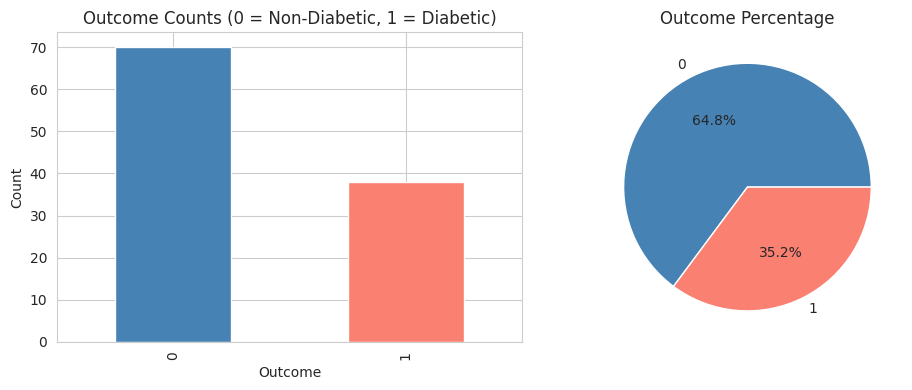

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
counts = df["Outcome"].value_counts()
counts.plot(kind="bar", ax=ax[0], color=["steelblue", "salmon"])
ax[0].set_title("Outcome Counts (0 = Non-Diabetic, 1 = Diabetic)")
ax[0].set_xlabel("Outcome")
ax[0].set_ylabel("Count")

counts.plot(kind="pie", autopct="%1.1f%%", ax=ax[1], colors=["steelblue", "salmon"])
ax[1].set_title("Outcome Percentage")
ax[1].set_ylabel("")
plt.tight_layout()
plt.show()

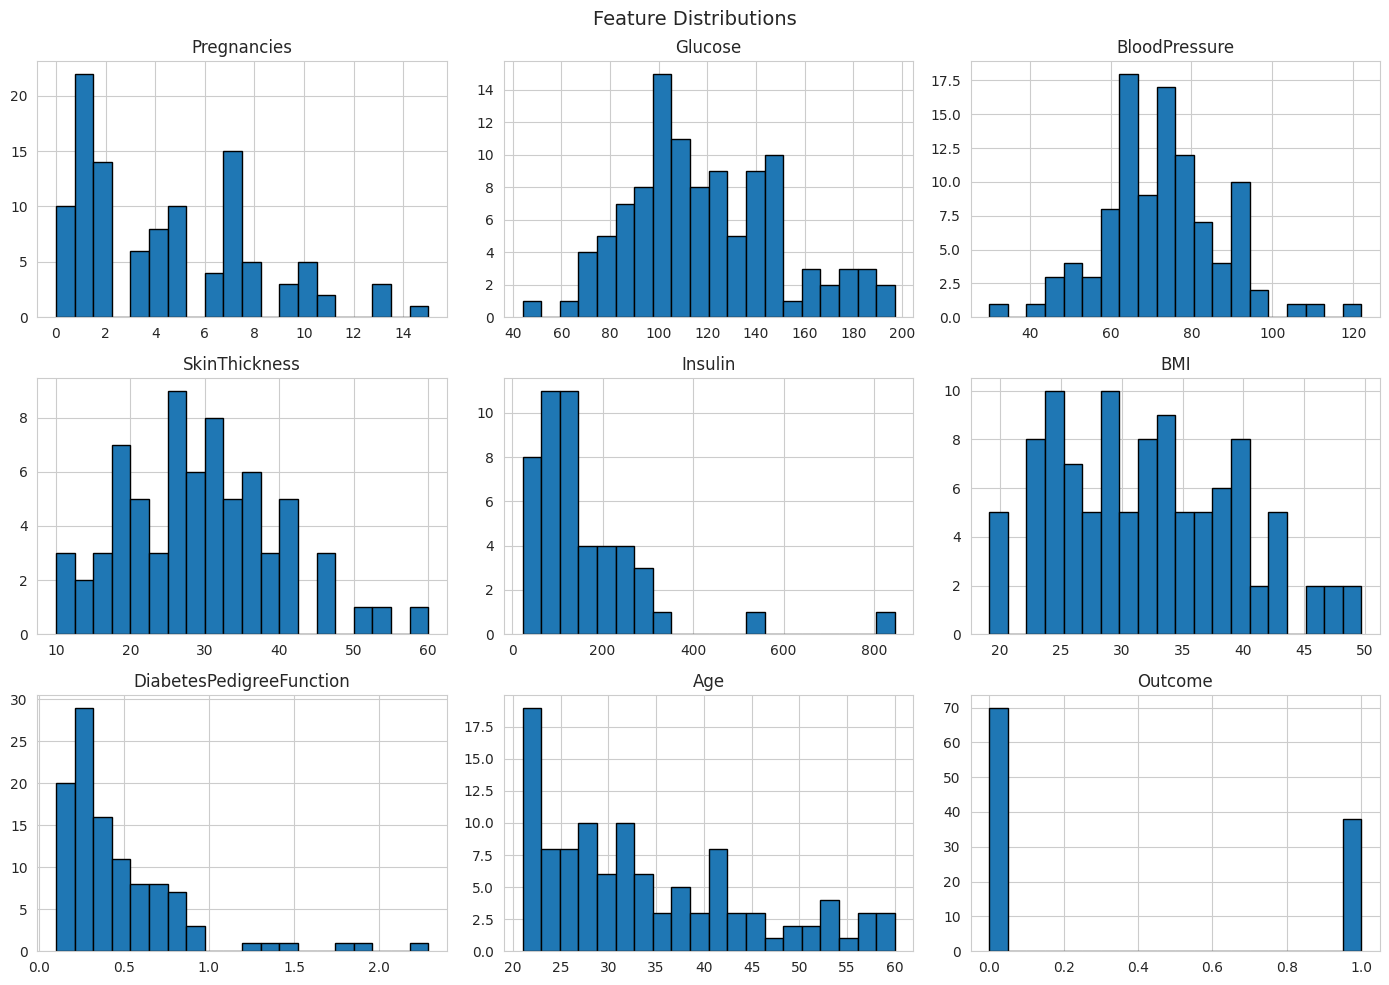

In [6]:
df_clean.hist(figsize=(14, 10), bins=20, edgecolor="black")
plt.suptitle("Feature Distributions", fontsize=14)
plt.tight_layout()
plt.show()

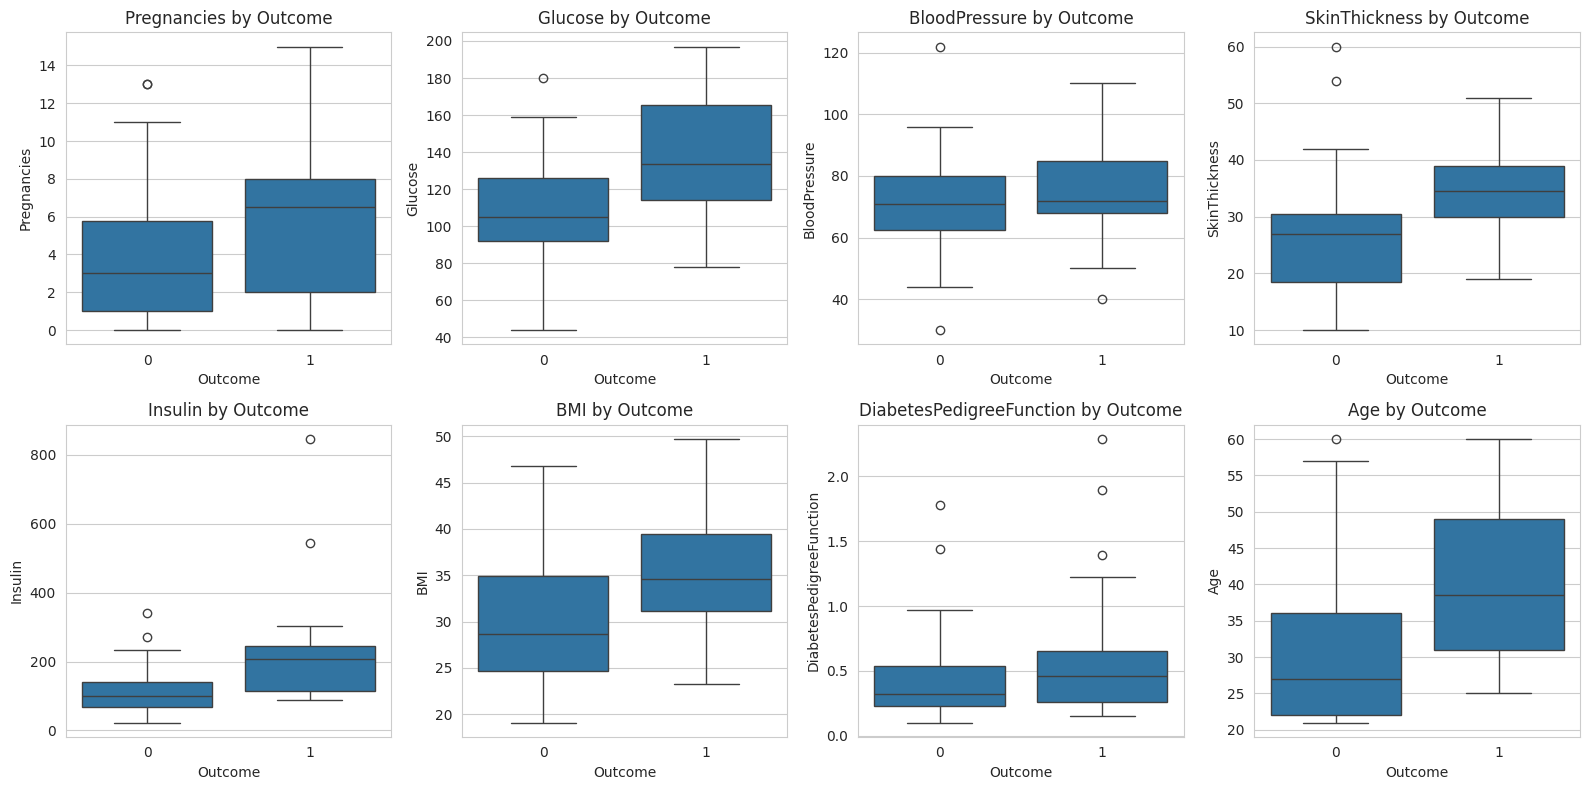

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
feature_cols = [c for c in df.columns if c != "Outcome"]
for ax, col in zip(axes.flat, feature_cols):
    sns.boxplot(data=df_clean, x="Outcome", y=col, ax=ax)
    ax.set_title(f"{col} by Outcome")
plt.tight_layout()
plt.show()

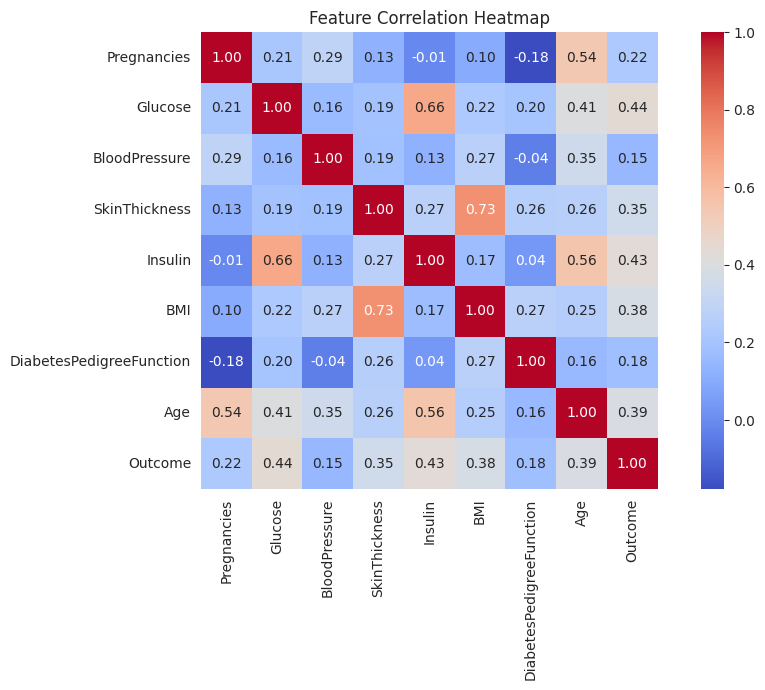

Top features correlated with Outcome:
Outcome                     1.000000
Glucose                     0.442480
Insulin                     0.431007
Age                         0.390658
BMI                         0.383072
SkinThickness               0.354657
Pregnancies                 0.223353
DiabetesPedigreeFunction    0.179346
BloodPressure               0.149779
Name: Outcome, dtype: float64


In [8]:
plt.figure(figsize=(10, 7))
corr = df_clean.corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", square=True)
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

print("Top features correlated with Outcome:")
print(corr["Outcome"].sort_values(ascending=False))

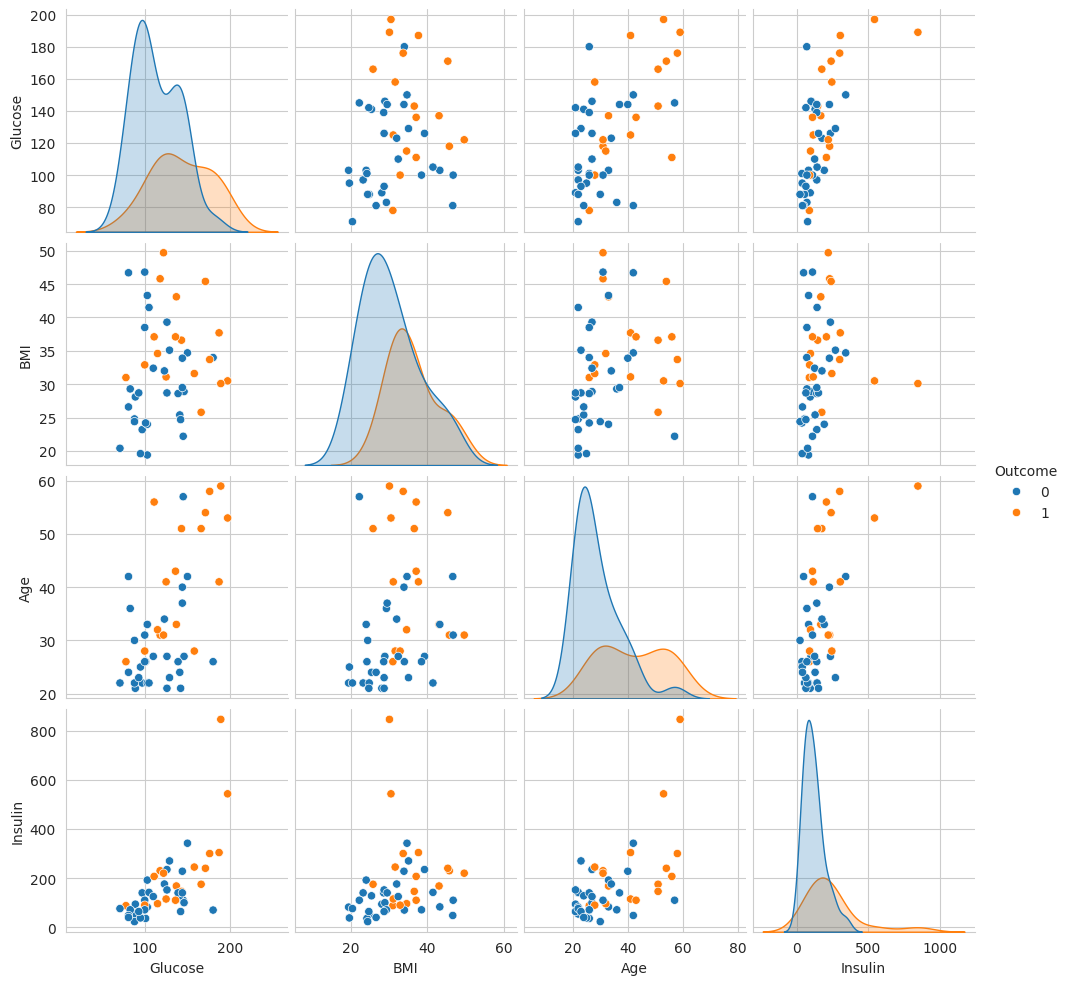

In [9]:
sns.pairplot(df_clean[["Glucose", "BMI", "Age", "Insulin", "Outcome"]].dropna(), hue="Outcome", diag_kind="kde")
plt.show()